# Hindcast skill vs. ensemble size

How does skill depend on ensemble size M, and what would an infinite ensemble give? All start years of each experiment are scored with ensemble means of M randomly chosen members (M = 1 … all). The dotted line is the fit ACC(M) = ACC∞ / √(1 + k/M) to the median curve (k is the noise-to-signal variance ratio), extended beyond the ensemble; the table lists the fitted ACC∞.

**Definitions** (identical to `stats.compute_skill_seasonal`, verified in `tests/test_sample_size_skill.py`):
ACC is the Pearson correlation of the ensemble-mean and observed anomalies over the selected years;
nRMSE is their RMSE divided by the observed standard deviation; with `DETREND = True` a linear trend
in initialization year is removed from both first. Area means average the score maps (cos-latitude
weights) over each region. Inputs are only read (test root first, then production): run 1a_atm (TS,
TREFHT, PRECT, PSL), 3a and 1a_lnd first for any field you want here. Shared loading, region means and
plotting live in `workflows/diagnostics/sample_size.py`.

Experiments: E3SMv3-FOSIRL and E3SMv3-Reanalysis, the two hindcasts with complete long records (May
starts 1980–2018), so the results rest on the full record.

In [1]:
# Test-run output roots (set before importing esp_lab so every module sees them).
import os
os.environ["ESP_LAB_FIGURE_ROOT"] = "/global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test"
os.environ["ESP_LAB_S2D_DIAG_ROOT"] = "/global/cfs/cdirs/e3sm/S2S2D/s2d_diag/tmp/e3sm-s2d_test"
os.environ["ESP_LAB_FIGURE_GALLERY"] = "0"  # test runs: figures only, no figures.json/index.html

%matplotlib inline
from pathlib import Path

import numpy as np
import pandas as pd

from esp_lab import env_paths
from esp_lab import sample_size_skill as sss
from workflows.diagnostics import sample_size as ss

In [2]:
# =============================================================================
# CONFIGURATION BLOCK: Edit settings here
# =============================================================================
INIT_MONTH = 5
RANDOM_SEED = 42
N_DRAWS = 100               # random subsets per sample size
RUN_GROUPS = ["atm", "sst", "lnd"]   # drop groups to shorten a run
QUICK = False               # True: 40 draws and the first field of each group only

# The two experiments with complete long hindcast records (May starts 1980-2018), so every
# curve rests on the full record. "years" is the start-year span a cache must lie within.
EXPERIMENTS = {
    "E3SM-FOSIRL":     dict(tag="JRA55_FOSIRL", label="E3SMv3-FOSIRL",     color="black",    years=(1980, 2018)),
    "E3SM-Reanalysis": dict(tag="Reanalysis",   label="E3SMv3-Reanalysis", color="tab:blue", years=(1980, 2018)),
}
MIN_YEARS = 6               # experiments with fewer observed start years are skipped for that field

ATM_FIELDS = ["TS", "TREFHT", "PRECT", "PSL"]
SST_INDICES = ["Nino3.4", "Nino3", "Nino4", "IOD", "TNA", "AtlNino"]
LAND_FIELDS = ["H2OSNO", "H2OSOI", "TWS"]

# Regions for gridded fields: (lat0, lat1, surface); land fields use finite land points.
ATM_REGIONS = {
    "Global 90S-90N": (-90, 90, "all"), "Land 60S-80N": (-60, 80, "land"),
    "Ocean 90S-90N": (-90, 90, "ocean"), "Tropics 20S-20N": (-20, 20, "all"),
}
LAND_REGIONS = {"Land 60S-80N": (-60, 80, "all"), "NH 30N-80N": (30, 80, "all")}

# Figures: one row per field/index, one column per lead (positions in each group's lead axis).
PLOT_REGION = {"atm": "Global 90S-90N", "lnd": "Land 60S-80N", "sst": "index"}
PLOT_LEADS = {"atm": [0, 2, 4], "sst": [0, 2, 4], "lnd": [0, 1, 2]}
DETREND = True
# ===== END CONFIGURATION BLOCK =====

## Inputs

For every experiment and field the longest cached record inside its span is used; only start years with observations are kept. The table lists what was found.

In [3]:
if QUICK:
    N_DRAWS = 40
    ATM_FIELDS, SST_INDICES, LAND_FIELDS = ATM_FIELDS[:1], SST_INDICES[:1], LAND_FIELDS[:1]

S2D_DIAG_ROOT = env_paths.s2d_diag_root()
READ_ROOTS = list(dict.fromkeys([S2D_DIAG_ROOT, Path("/global/cfs/cdirs/e3sm/S2S2D/s2d_diag")]))
FIGURE_DIR = env_paths.figure_root() / "sample_size"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR = S2D_DIAG_ROOT / "multimodel" / "sample_size"
TABLE_DIR.mkdir(parents=True, exist_ok=True)
rng = np.random.default_rng(RANDOM_SEED)

GROUP_FIELDS = {"atm": ATM_FIELDS, "sst": SST_INDICES, "lnd": LAND_FIELDS}
DATA, inventory = ss.load_inputs(
    {group: GROUP_FIELDS[group] for group in RUN_GROUPS}, EXPERIMENTS,
    read_roots=READ_ROOTS, init_month=INIT_MONTH, min_years=MIN_YEARS,
)
REDUCE = ss.region_reducers(READ_ROOTS, ATM_REGIONS, LAND_REGIONS)
PLOT = dict(experiments=EXPERIMENTS, plot_region=PLOT_REGION, plot_leads=PLOT_LEADS)
print(f"Read roots: {[str(r) for r in READ_ROOTS]}\nFigures: {FIGURE_DIR}\nTables: {TABLE_DIR}")
inventory.drop(columns="file", errors="ignore").fillna("")

Read roots: ['/global/cfs/cdirs/e3sm/S2S2D/s2d_diag/tmp/e3sm-s2d_test', '/global/cfs/cdirs/e3sm/S2S2D/s2d_diag']
Figures: /global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_size
Tables: /global/cfs/cdirs/e3sm/S2S2D/s2d_diag/tmp/e3sm-s2d_test/multimodel/sample_size


,group,field,experiment,status,years,n_years,members
0,atm,TS,E3SM-FOSIRL,used,1980-2017,38,10
1,atm,TS,E3SM-Reanalysis,used,1980-2017,38,10
2,atm,TREFHT,E3SM-FOSIRL,used,1980-2017,38,10
3,atm,TREFHT,E3SM-Reanalysis,used,1980-2017,38,10
4,atm,PRECT,E3SM-FOSIRL,used,1980-2015,36,10
5,atm,PRECT,E3SM-Reanalysis,used,1980-2015,36,10
6,atm,PSL,E3SM-FOSIRL,used,1980-2011,32,10
7,atm,PSL,E3SM-Reanalysis,used,1980-2011,32,10
8,sst,Nino3.4,E3SM-FOSIRL,used,1980-2018,39,10
9,sst,Nino3.4,E3SM-Reanalysis,used,1980-2018,39,10


## Skill vs. ensemble size

/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,


/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,


/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,


/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,


/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,


/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,


... (132 outputs left out)

/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,


/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,


done: lnd H2OSOI
done: lnd TWS


Saved /global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_size/fig_sample_size_members_acc_atm.png


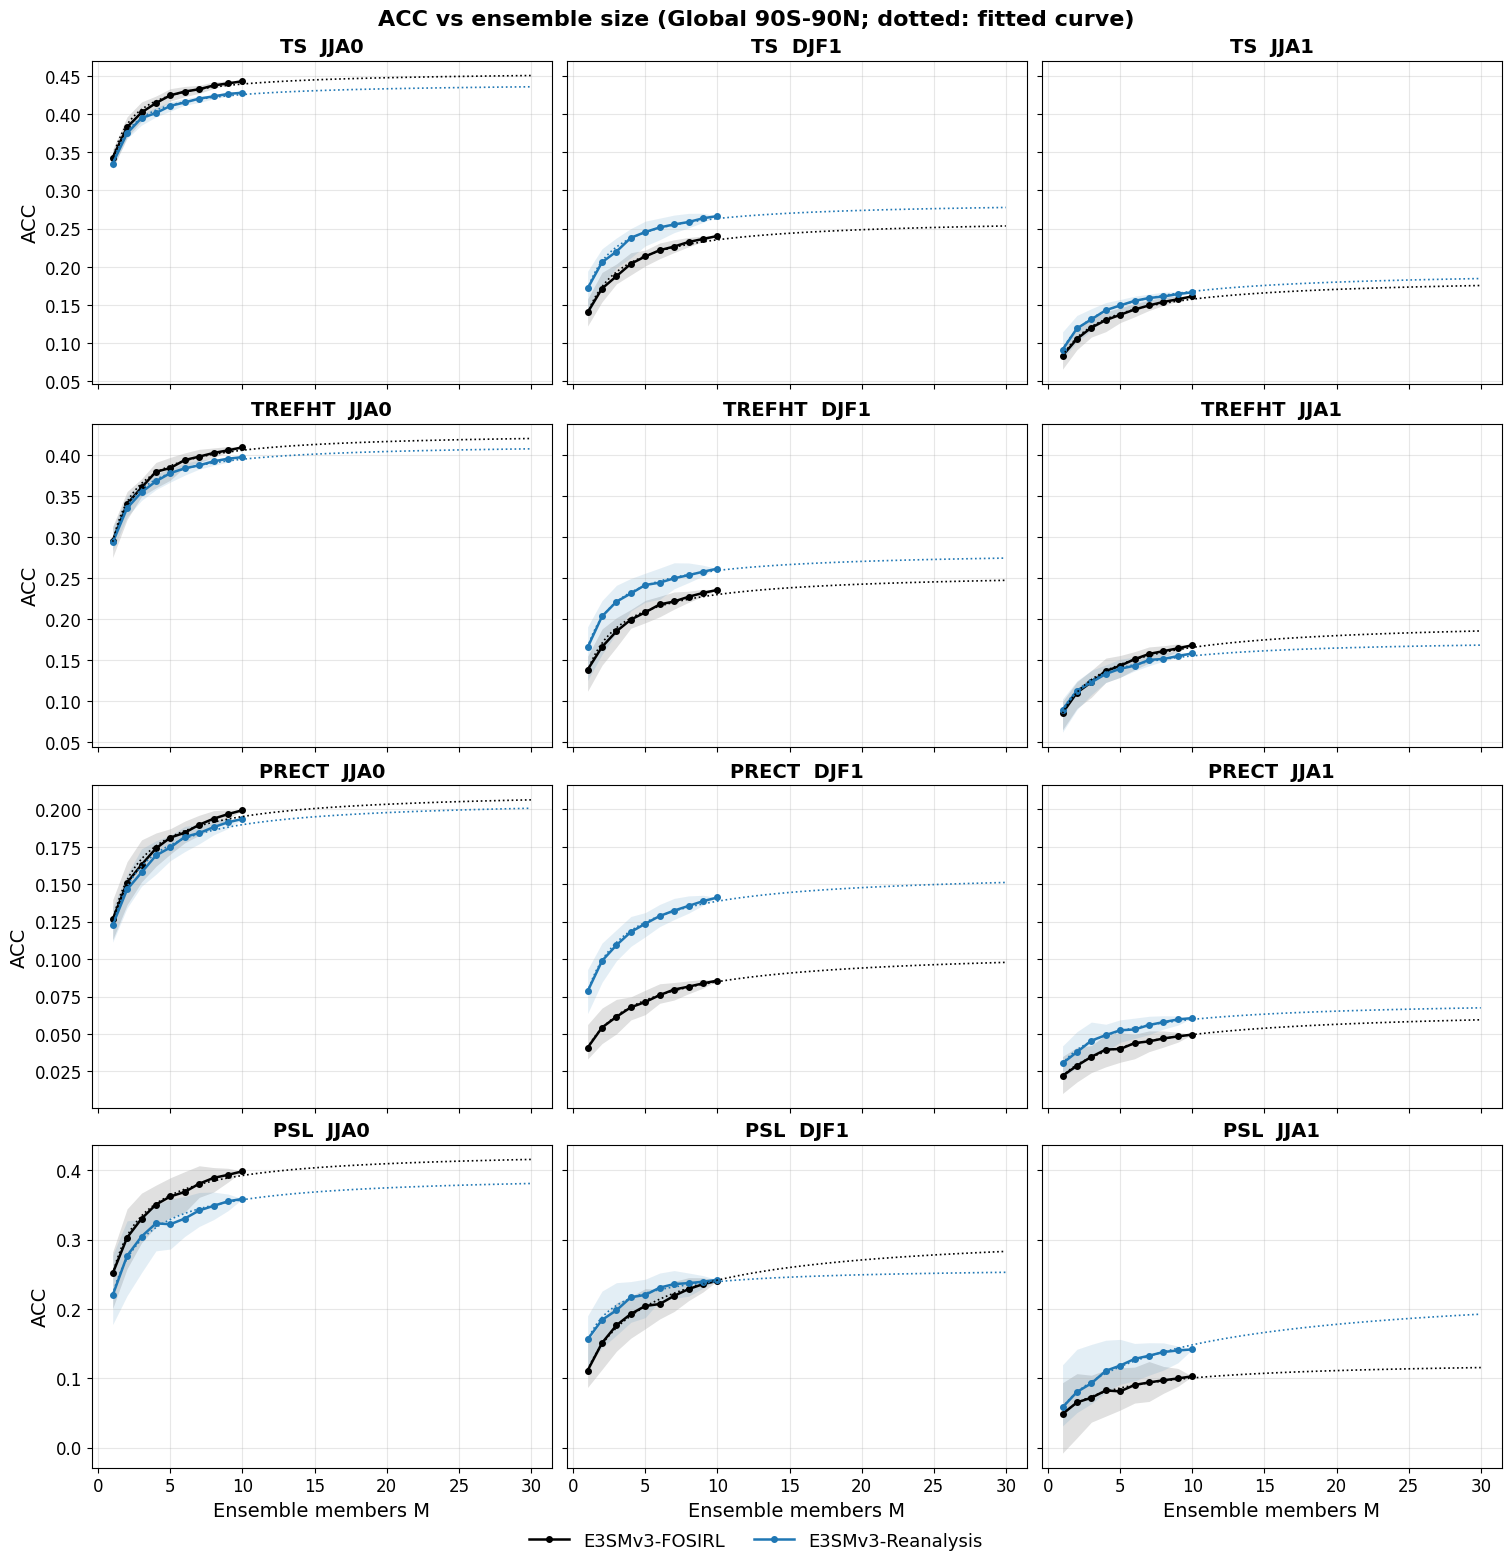

/global/u2/z/zhan391/code/ESP-Lab/esp_lab/sample_size_skill.py:279: RuntimeWarning: invalid value encountered in sqrt
  return acc_inf / np.sqrt(1.0 + ratio / m)


Saved /global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_size/fig_sample_size_members_acc_sst.png


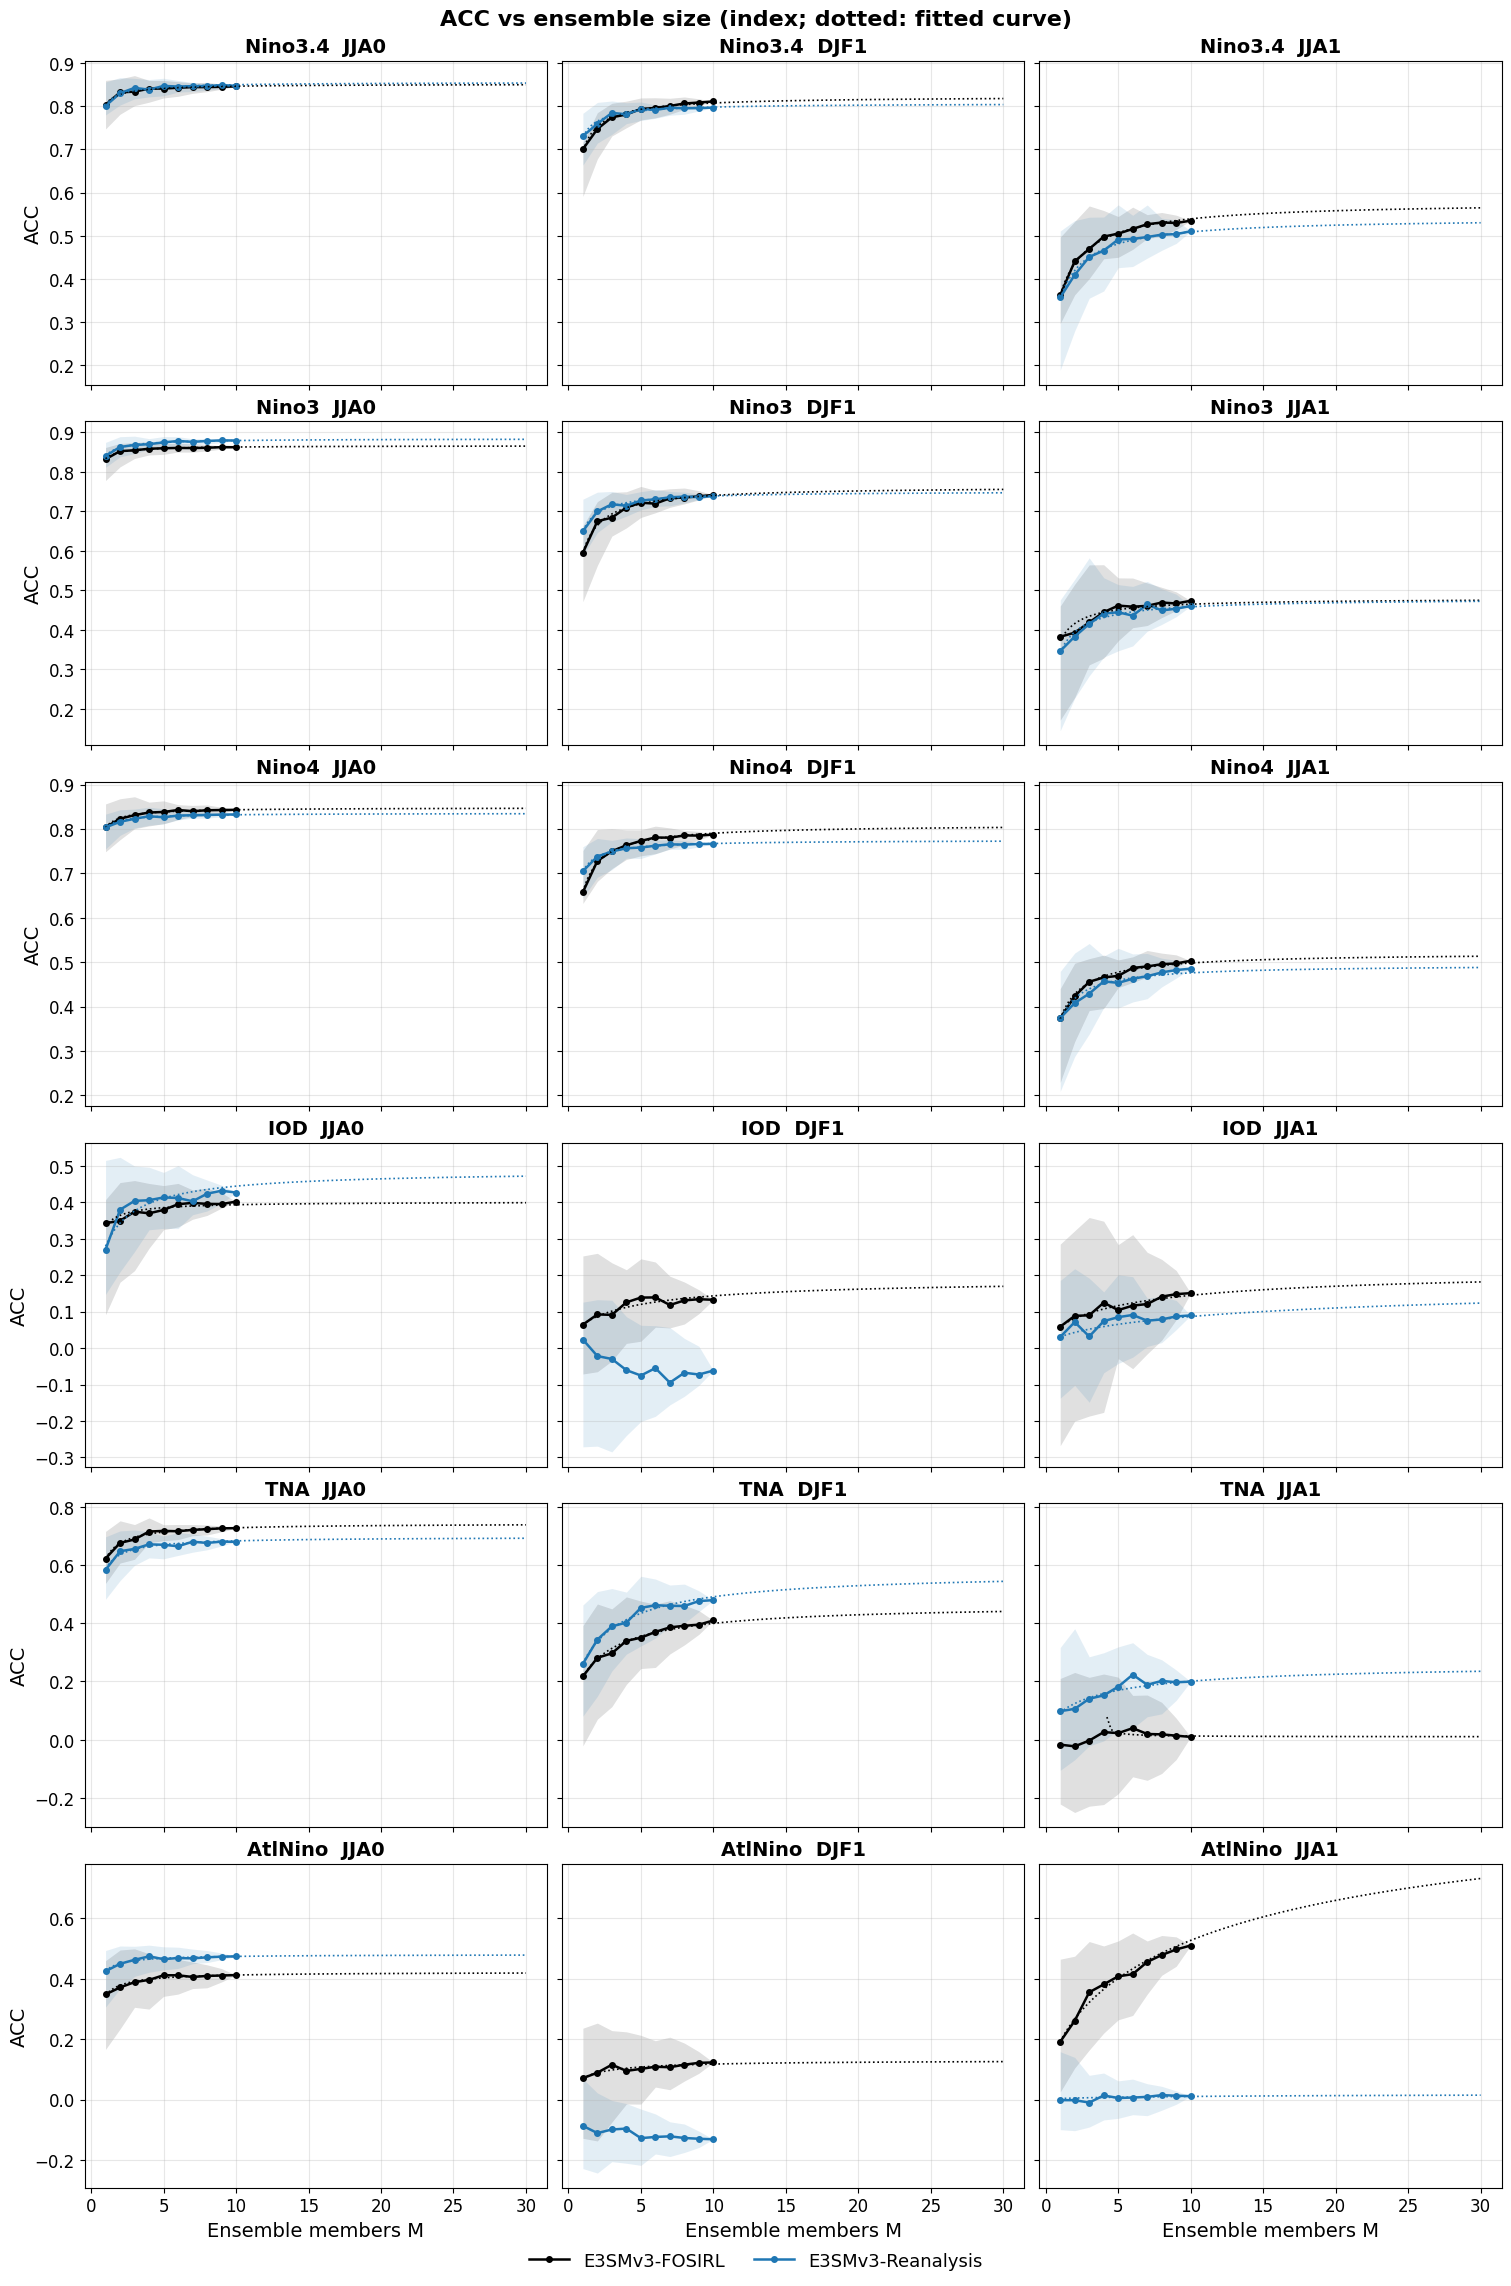

Saved /global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_size/fig_sample_size_members_acc_lnd.png


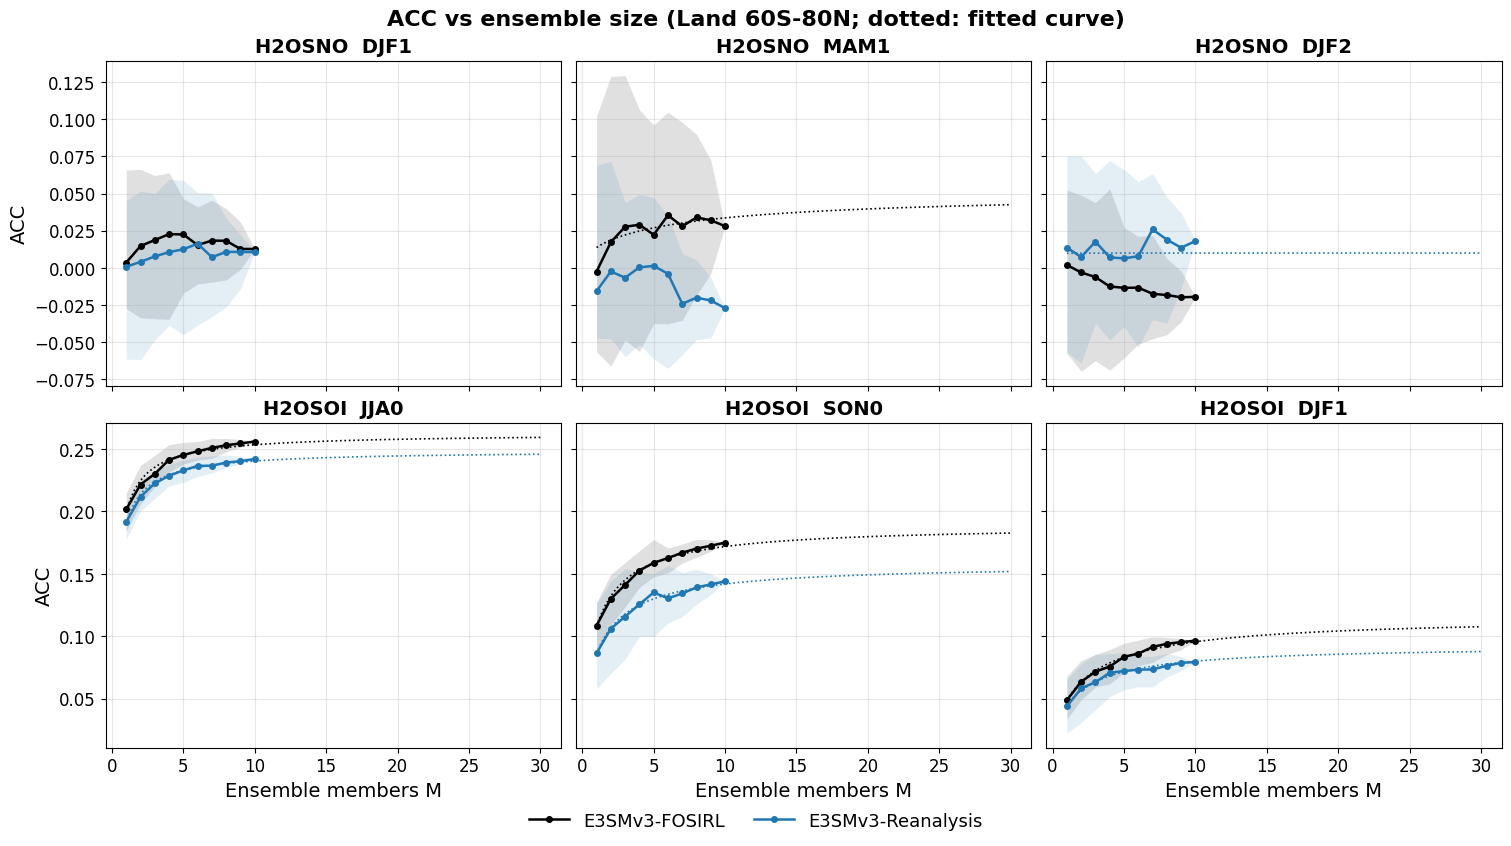

In [4]:
rows, fits = [], []
for group, fields in DATA.items():
    for field, experiments in fields.items():
        for key, d in experiments.items():
            members = d["members"]
            for m in range(1, members.sizes["M"] + 1):
                weights = sss.random_subsets(members.sizes["M"], m, N_DRAWS // 2, rng)
                scores = sss.member_subset_scores(members, d["obs"], weights, detrend=DETREND, reduce=REDUCE[group])
                rows += ss.summarize(scores, ["acc", "nrmse"], group=group, field=field, experiment=key, members=m)
        print(f"done: {group} {field}")
ensemble = pd.DataFrame(rows)
for (group, field, key, region, lead), curve in ensemble[ensemble.metric == "acc"].groupby(
        ["group", "field", "experiment", "region", "lead"]):
    acc_inf, ratio = sss.fit_member_curve(curve.members, curve["median"])
    fits.append(dict(group=group, field=field, experiment=key, region=region, lead=lead,
                     members=int(curve.members.max()), acc_full=float(curve["median"].iloc[-1]),
                     acc_inf=acc_inf, noise_to_signal=ratio))
fits = pd.DataFrame(fits)
ensemble.to_csv(TABLE_DIR / f"sample_size_members_init{INIT_MONTH:02d}.csv", index=False)
fits.to_csv(TABLE_DIR / f"sample_size_members_acc_inf_init{INIT_MONTH:02d}.csv", index=False)


def member_fit(ax, group, field, lead, panel):
    m = np.linspace(1, max(int(panel.members.max()), 20) * 1.5, 100)
    for key, info in EXPERIMENTS.items():
        f = fits[(fits.group == group) & (fits.field == field) & (fits.experiment == key)
                 & (fits.region == PLOT_REGION[group]) & (fits.lead == lead)]
        if not f.empty and np.isfinite(f.acc_inf.iloc[0]):
            ax.plot(m, sss.member_curve(f.acc_inf.iloc[0], f.noise_to_signal.iloc[0], m), ":", color=info["color"], lw=1.2)


for group in DATA:
    ss.plot_curves(ensemble, DATA, group, "members", "ACC", f"ACC vs ensemble size ({PLOT_REGION[group]}; dotted: fitted curve)",
                   FIGURE_DIR / f"fig_sample_size_members_acc_{group}.png", metric="acc", extra=member_fit, **PLOT)

## Fitted infinite-ensemble ACC

ACC∞ by lead (columns) for the plotted region; `noise_to_signal` and the full-ensemble ACC are in the saved table.

In [5]:
(fits[fits.region.isin(PLOT_REGION.values())]
 .pivot_table(index=["group", "field", "experiment"], columns="lead", values="acc_inf").round(2))

lead                              0     1     2     3     4     5     6
group field   experiment                                               
atm   PRECT   E3SM-FOSIRL      0.19  0.16  0.09  0.05  0.10  0.00  0.07
              E3SM-Reanalysis  0.20  0.13  0.14  0.11  0.16  0.05  0.12
      PSL     E3SM-FOSIRL      0.43  0.23  0.57  0.20  0.14  0.04  0.20
              E3SM-Reanalysis  0.39  0.21  0.19  0.19  0.20  0.09  0.17
      TREFHT  E3SM-FOSIRL      0.35  0.26  0.17  0.37  0.22  0.14  0.14
              E3SM-Reanalysis  0.34  0.21  0.21  0.18  0.18  0.08  0.15
      TS      E3SM-FOSIRL      0.36  0.28  0.17  0.23  0.22  0.16  0.13
              E3SM-Reanalysis  0.35  0.23  0.21  0.18  0.18  0.09  0.16
lnd   H2OSNO  E3SM-FOSIRL       NaN  0.05   NaN   NaN   NaN   NaN   NaN
              E3SM-Reanalysis   NaN   NaN  0.01   NaN   NaN   NaN   NaN
      H2OSOI  E3SM-FOSIRL      0.26  0.19  0.12  0.07  0.03   NaN   NaN
              E3SM-Reanalysis  0.25  0.16  0.09  0.07  0.01  0.00  0.04
sst   AtlNino E3SM-FOSIRL      0.42  0.23  0.13  0.07  1.00  0.67  0.41
              E3SM-Reanalysis  0.48  0.15   NaN   NaN  0.02   NaN  0.11
      IOD     E3SM-FOSIRL      0.40  0.61  0.19  0.02  0.21  0.60   NaN
              E3SM-Reanalysis  0.49  0.46   NaN  0.01  0.18  0.31   NaN
      Nino3   E3SM-FOSIRL      0.87  0.78  0.76  0.39  0.48  0.48  0.48
              E3SM-Reanalysis  0.88  0.78  0.75  0.51  0.48  0.70  0.83
      Nino3.4 E3SM-FOSIRL      0.85  0.83  0.82  0.68  0.58  0.52  0.52
              E3SM-Reanalysis  0.86  0.82  0.81  0.61  0.54  0.69  0.72
      Nino4   E3SM-FOSIRL      0.85  0.82  0.81  0.74  0.52  0.49  0.48
              E3SM-Reanalysis  0.84  0.80  0.78  0.69  0.49  0.64  0.67
      TNA     E3SM-FOSIRL      0.74  0.59  0.47   NaN  0.01   NaN   NaN
              E3SM-Reanalysis  0.70  0.49  0.58  0.60  0.26  0.30  0.16